In [92]:
import torch
import numpy as np 
import pandas as pd 
import sklearn
import os
import random
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F

In [93]:
def set_seed(seed: int = 42, deterministic: bool = True):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
        torch.use_deterministic_algorithms(True, warn_only=True)


def get_device(prefer: str = "auto") -> torch.device:
    if prefer == "cpu":
        return torch.device("cpu")
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():  
        return torch.device("mps")
    return torch.device("cpu")

In [94]:
SEED = 42
set_seed(SEED)
device = get_device()
print(f"Device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cpu


In [95]:
raw = np.load("data\\Nonlinear_data.npy", allow_pickle=True)
data = raw.item()

In [96]:
X = data['X']
y = data['labels']

In [97]:
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (300, 2)
y shape: (300,)


In [98]:
from sklearn.model_selection import train_test_split

# 70% train, 20% val, 10% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=1/3, random_state=SEED
)

In [99]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [100]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)


In [101]:
def CustomDataset(X, y):
    class CustomDataset(Dataset):
        def __init__(self, X, y):
            self.X = X
            self.y = y

        def __len__(self):
            return len(self.X)

        def __getitem__(self, idx):
            return self.X[idx], self.y[idx]

    return CustomDataset(X, y)

train_dataset = CustomDataset(X_train, y_train)
val_dataset = CustomDataset(X_val, y_val)
test_dataset = CustomDataset(X_test, y_test)

In [102]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [103]:
class MLP(nn.Module):
    def __init__(self, input_dims, hidden_dims=128, num_classes=None):
        super(MLP, self).__init__()
        # Tự động lấy số class nếu num_classes chưa được truyền trực tiếp
        if num_classes is None:
            num_classes = torch.unique(y_train).shape[0]
            
        # 1 lớp ẩn: input_dim -> hidden_dim
        self.fc1 = nn.Linear(input_dims, hidden_dims)
        # Lớp đầu ra: hidden_dim -> output_dim (num_classes)
        self.fc2 = nn.Linear(hidden_dims, num_classes)

    def forward(self, x):
        # Đi qua lớp ẩn và kích hoạt phi tuyến
        x = F.relu(self.fc1(x))
        # Đi qua lớp output, trả về logits thô (không ReLU, không squeeze)
        x = self.fc2(x)
        return x

In [104]:
input_dims = X_train.shape[1]
hidden_dims = 128
model = MLP(
    input_dims=input_dims,
    hidden_dims=hidden_dims
)

In [105]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

In [106]:
def compute_accuracy(y_pred, y_true):
    _, predicted_classes = torch.max(y_pred, dim=1)

    correct = (predicted_classes == y_true).sum().item()

    accuracy = correct / y_true.size(0)

    return accuracy

In [107]:
epochs = 100
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    # =========================
    # TRAIN
    # =========================
    model.train()

    total_train_loss = 0

    train_preds = []
    train_targets = []

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

        train_preds.append(outputs.detach().cpu())
        train_targets.append(y_batch.detach().cpu())

    train_loss = total_train_loss / len(train_loader.dataset)

    train_preds = torch.cat(train_preds)
    train_targets = torch.cat(train_targets)

    train_acc = compute_accuracy(
        train_preds,
        train_targets
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)


    # =========================
    # VALIDATION
    # =========================
    model.eval()

    total_val_loss = 0

    val_preds = []
    val_targets = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            total_val_loss += loss.item() * X_batch.size(0)

            val_preds.append(outputs.detach().cpu())
            val_targets.append(y_batch.detach().cpu())

    val_loss = total_val_loss / len(val_loader.dataset)

    val_preds = torch.cat(val_preds)
    val_targets = torch.cat(val_targets)

    val_acc = compute_accuracy(
        val_preds,
        val_targets
    )

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)


    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    train_preds = []
    train_targets = []

Epoch 1/100 | Train Loss: 0.9826 | Train Acc: 0.5286 | Val Loss: 0.8859 | Val Acc: 0.4667
Epoch 2/100 | Train Loss: 0.8145 | Train Acc: 0.5524 | Val Loss: 0.7683 | Val Acc: 0.5167
Epoch 3/100 | Train Loss: 0.7236 | Train Acc: 0.5714 | Val Loss: 0.7388 | Val Acc: 0.4667
Epoch 4/100 | Train Loss: 0.6903 | Train Acc: 0.5952 | Val Loss: 0.7228 | Val Acc: 0.5000
Epoch 5/100 | Train Loss: 0.6764 | Train Acc: 0.6000 | Val Loss: 0.7032 | Val Acc: 0.5167
Epoch 6/100 | Train Loss: 0.6582 | Train Acc: 0.6000 | Val Loss: 0.6796 | Val Acc: 0.5333
Epoch 7/100 | Train Loss: 0.6420 | Train Acc: 0.6095 | Val Loss: 0.6642 | Val Acc: 0.5333
Epoch 8/100 | Train Loss: 0.6230 | Train Acc: 0.6476 | Val Loss: 0.6474 | Val Acc: 0.6167
Epoch 9/100 | Train Loss: 0.6066 | Train Acc: 0.6714 | Val Loss: 0.6262 | Val Acc: 0.6000
Epoch 10/100 | Train Loss: 0.5913 | Train Acc: 0.6714 | Val Loss: 0.6074 | Val Acc: 0.6000
Epoch 11/100 | Train Loss: 0.5805 | Train Acc: 0.6714 | Val Loss: 0.5930 | Val Acc: 0.6000
Epoch 12

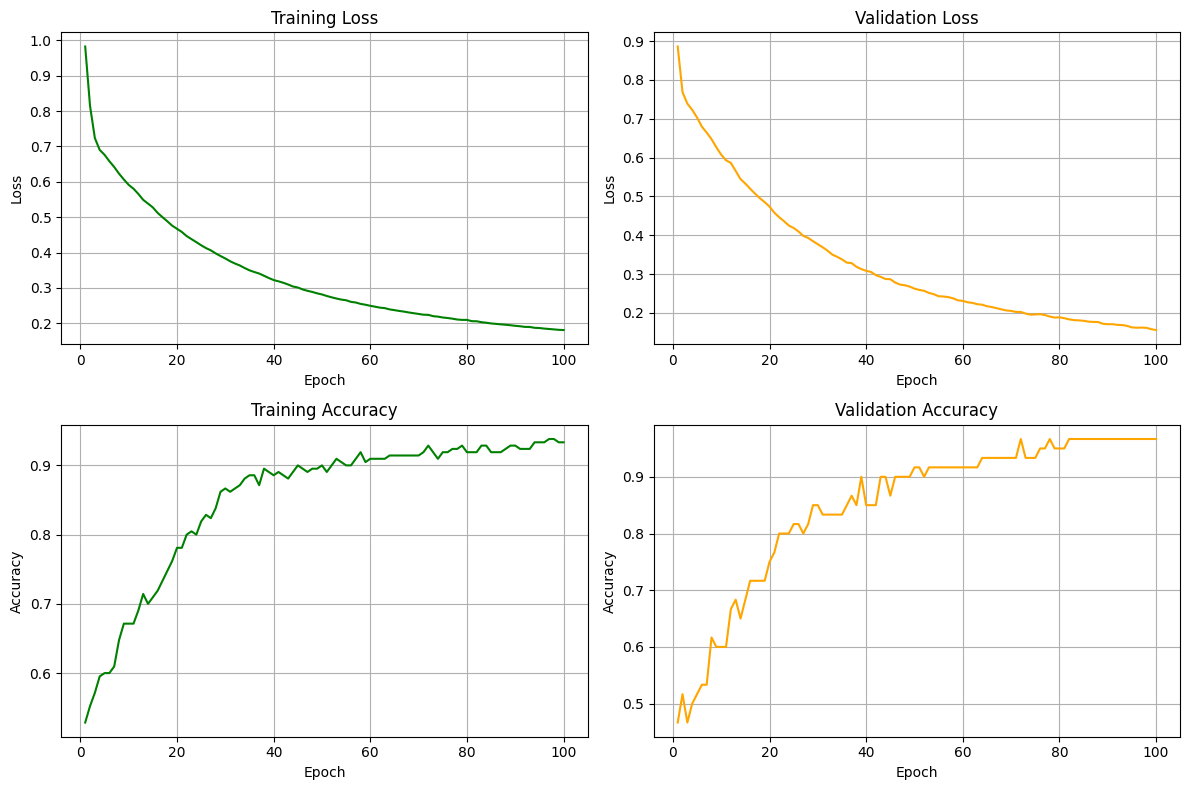

In [108]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Training Loss
axes[0, 0].plot(
    epochs_range,
    train_losses,
    color="green"
)
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].grid(True)

# Validation Loss
axes[0, 1].plot(
    epochs_range,
    val_losses,
    color="orange"
)
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].grid(True)

# Training Accuracy
axes[1, 0].plot(
    epochs_range,
    train_accuracies,
    color="green"
)
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].grid(True)

# Validation Accuracy
axes[1, 1].plot(
    epochs_range,
    val_accuracies,
    color="orange"
)
axes[1, 1].set_title("Validation Accuracy")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [109]:
model.eval()

test_preds = []
test_targets = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(X_batch)

        test_preds.append(outputs.detach().cpu())
        test_targets.append(y_batch.detach().cpu())


test_preds = torch.cat(test_preds)
test_targets = torch.cat(test_targets)

test_accuracy = compute_accuracy(
    test_preds,
    test_targets
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 1.0000
Test Accuracy: 100.00%
